# 🔍 Fraud Detection - Tổng Hợp Ba Dataset

**Notebook Google Colab-ready** | Nhóm 01 - GDG HUST

Notebook này tổng hợp toàn bộ pipeline phát hiện gian lận (fraud detection) trên ba bộ dữ liệu:

| # | Dataset | Nguồn | Target |
|---|---------|-------|--------|
| 1 | Credit Card Fraud | Kaggle: mlg-ulb/creditcardfraud | `Class` (0/1) |
| 2 | IEEE-CIS Fraud Detection | Kaggle Competition: ieee-fraud-detection | `isFraud` |
| 3 | PaySim Synthetic Mobile Money | Kaggle: ealaxi/paysim1 | `isFraud` |

**Các mô hình được sử dụng:** Logistic Regression, LightGBM, XGBoost, CatBoost

---

## Phần 0: Cài đặt môi trường

Cài đặt tất cả các thư viện cần thiết. Chạy cell này trước tiên khi dùng Google Colab.

In [90]:
!pip install kagglehub lightgbm xgboost catboost scikit-learn pandas numpy matplotlib seaborn imbalanced-learn -q


'pip' is not recognized as an internal or external command,
operable program or batch file.


### 0.1 Cấu hình Kaggle API

Để tải dataset từ Kaggle, bạn cần cấu hình credentials. Trên Google Colab:
1. Vào **Settings** → **Secrets** của Colab
2. Thêm `KAGGLE_USERNAME` và `KAGGLE_KEY` (lấy từ Kaggle → Account → API)
3. Hoặc upload file `kaggle.json` trực tiếp

In [91]:
import os


def setup_kaggle():
    """Setup Kaggle credentials từ Google Drive hoặc environment variables."""
    try:
        from google.colab import userdata

        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        print("✅ Kaggle credentials loaded from Colab secrets")
    except Exception:
        # Local: đặt biến môi trường hoặc dùng kaggle.json
        print("ℹ️  Colab secrets không có, dùng kaggle.json hoặc env vars đã set sẵn")


setup_kaggle()


ℹ️  Colab secrets không có, dùng kaggle.json hoặc env vars đã set sẵn


### 0.2 Hàm Benchmark Chung

Hàm `benchmark()` được dùng thống nhất để đánh giá tất cả các mô hình.
Các chỉ số: **Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC** và **Confusion Matrix**.

In [92]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

results_table = []  # Danh sách tổng hợp kết quả tất cả models


def benchmark(name, y_true, y_pred_proba, threshold=0.5):
    """Đánh giá mô hình với các chỉ số phổ biến cho bài toán phát hiện gian lận."""
    y_pred = (y_pred_proba > threshold).astype(int)
    results = {
        "Model": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_true, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_true, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_true, y_pred_proba), 4),
        "PR-AUC": round(average_precision_score(y_true, y_pred_proba), 4),
    }
    print(f"\n{'=' * 55}")
    print(f"Model: {name}")
    for k, v in results.items():
        if k != "Model":
            print(f"  {k:12s}: {v}")
    cm = confusion_matrix(y_true, y_pred)
    print(f"  Confusion Matrix:\n{cm}")
    return results


print("✅ Hàm benchmark đã sẵn sàng.")


✅ Hàm benchmark đã sẵn sàng.


---
# PHẦN 1: Credit Card Fraud Detection

Dataset giao dịch thẻ tín dụng của ngân hàng Châu Âu (tháng 9/2013).
- **Nguồn:** Kaggle - [mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)
- **Kích thước:** 284,807 giao dịch, 492 gian lận (~0.17%)
- **Features:** V1-V28 (PCA), Amount, Time
- **Target:** `Class` (0 = hợp lệ, 1 = gian lận)

## 1.1 Giới thiệu Dataset

Do tính bảo mật, hầu hết các feature gốc đã được xử lý qua PCA thành V1-V28.
Chỉ có `Time` và `Amount` là các feature gốc không được biến đổi.

**Thách thức chính:** Class imbalance nghiêm trọng (99.83% vs 0.17%).

## 1.2 Load Dữ liệu

Tải dataset trực tiếp từ Kaggle qua `kagglehub`.

In [ ]:
import kagglehub
import os
import glob

# Tải dataset Credit Card Fraud
print("📥 Đang tải dataset Credit Card Fraud...")
cc_path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print(f"✅ Dataset tải về tại: {cc_path}")

# Tìm file CSV
cc_files = glob.glob(os.path.join(cc_path, "**", "*.csv"), recursive=True)
print(f"Files CSV tìm thấy: {cc_files}")
cc_csv = cc_files[0]
print(f"Dùng file: {cc_csv}")


📥 Đang tải dataset Credit Card Fraud...
✅ Dataset tải về tại: C:\Users\Thaibh\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3
Files CSV tìm thấy: ['C:\\Users\\Thaibh\\.cache\\kagglehub\\datasets\\mlg-ulb\\creditcardfraud\\versions\\3\\creditcard.csv']
Dùng file: C:\Users\Thaibh\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3\creditcard.csv


In [ ]:
df_cc = pd.read_csv(cc_csv)
print(f"Shape: {df_cc.shape}")
print(f"\nPhân phối class:")
print(df_cc["Class"].value_counts())
print(f"\nTỷ lệ fraud: {df_cc['Class'].mean() * 100:.4f}%")
df_cc.head(3)


Shape: (284807, 31)

Phân phối class:
Class
0    284315
1       492
Name: count, dtype: int64

Tỷ lệ fraud: 0.1727%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


## 1.3 Exploratory Data Analysis (EDA)

Phân tích sơ bộ phân phối dữ liệu và mức độ mất cân bằng class.

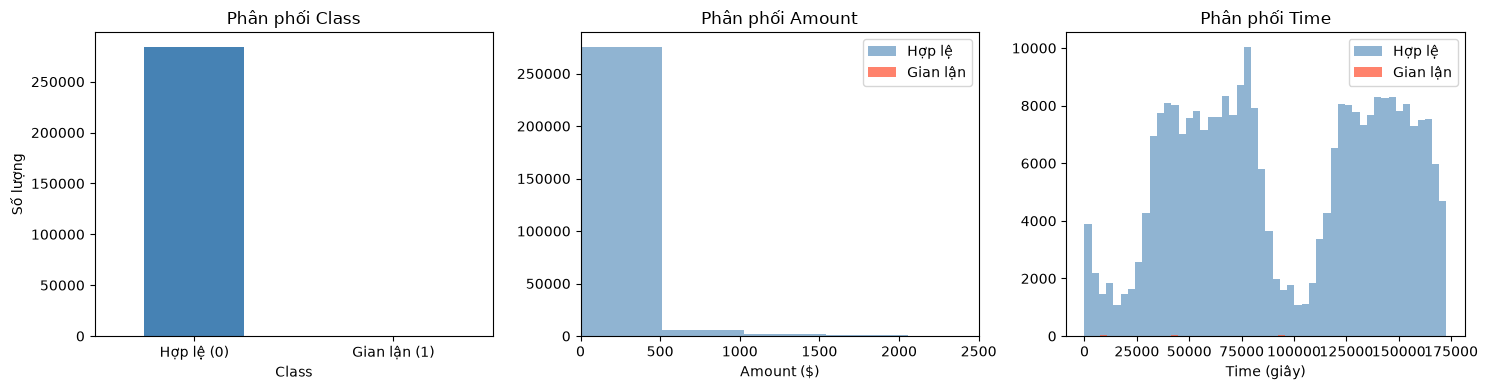

Missing values: 0


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Class distribution
df_cc["Class"].value_counts().plot(
    kind="bar", ax=axes[0], color=["steelblue", "tomato"]
)
axes[0].set_title("Phân phối Class")
axes[0].set_xticklabels(["Hợp lệ (0)", "Gian lận (1)"], rotation=0)
axes[0].set_ylabel("Số lượng")

# Amount distribution
axes[1].hist(
    df_cc[df_cc["Class"] == 0]["Amount"],
    bins=50,
    alpha=0.6,
    label="Hợp lệ",
    color="steelblue",
)
axes[1].hist(
    df_cc[df_cc["Class"] == 1]["Amount"],
    bins=50,
    alpha=0.8,
    label="Gian lận",
    color="tomato",
)
axes[1].set_title("Phân phối Amount")
axes[1].set_xlabel("Amount ($)")
axes[1].legend()
axes[1].set_xlim(0, 2500)

# Time distribution
axes[2].hist(
    df_cc[df_cc["Class"] == 0]["Time"],
    bins=50,
    alpha=0.6,
    label="Hợp lệ",
    color="steelblue",
)
axes[2].hist(
    df_cc[df_cc["Class"] == 1]["Time"],
    bins=50,
    alpha=0.8,
    label="Gian lận",
    color="tomato",
)
axes[2].set_title("Phân phối Time")
axes[2].set_xlabel("Time (giây)")
axes[2].legend()

plt.tight_layout()
plt.show()
print("Missing values:", df_cc.isnull().sum().sum())


## 1.4 Preprocessing & Train/Test Split

- Chuẩn hóa `Amount` và `Time` bằng `StandardScaler`
- Chia 80/20 theo `StratifiedShuffleSplit` để giữ tỷ lệ class

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_cc = df_cc.drop(columns=["Class"])
y_cc = df_cc["Class"]

# Scale Amount và Time
scaler = StandardScaler()
X_cc[["Amount", "Time"]] = scaler.fit_transform(X_cc[["Amount", "Time"]])

X_train_cc, X_test_cc, y_train_cc, y_test_cc = train_test_split(
    X_cc, y_cc, test_size=0.2, random_state=42, stratify=y_cc
)

print(f"Train: {X_train_cc.shape}, Test: {X_test_cc.shape}")
print(f"Train fraud rate: {y_train_cc.mean():.4f}")
print(f"Test fraud rate:  {y_test_cc.mean():.4f}")


Train: (227845, 30), Test: (56962, 30)
Train fraud rate: 0.0017
Test fraud rate:  0.0017


## 1.5 Mô Hình Baseline: Logistic Regression

Sử dụng class_weight='balanced' để xử lý imbalanced data.

In [97]:
from sklearn.linear_model import LogisticRegression

lr_cc = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr_cc.fit(X_train_cc, y_train_cc)

lr_proba_cc = lr_cc.predict_proba(X_test_cc)[:, 1]
res = benchmark("CC - Logistic Regression", y_test_cc, lr_proba_cc)
results_table.append(res)



Model: CC - Logistic Regression
  Accuracy    : 0.9755
  Precision   : 0.0609
  Recall      : 0.9184
  F1          : 0.1141
  ROC-AUC     : 0.9722
  PR-AUC      : 0.7189
  Confusion Matrix:
[[55475  1389]
 [    8    90]]


## 1.6 Mô Hình Tree-based: LightGBM + XGBoost + CatBoost

Sử dụng **5-fold StratifiedKFold** Cross-Validation, lấy trung bình xác suất dự đoán (OOF).

> **Lý do dùng CV:** Với dữ liệu imbalanced, CV cho kết quả ổn định hơn so với single split.

In [ ]:
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb
import xgboost as xgb
import catboost as cb

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_full_cc = X_cc.values
y_full_cc = y_cc.values

# ─── LightGBM ───────────────────────────────────────────────────────────────
print("🌳 Training LightGBM (5-fold CV)...")
oof_lgb_cc = np.zeros(len(y_full_cc))

lgb_params = {
    "objective": "binary",
    "metric": "auc",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "scale_pos_weight": int((y_full_cc == 0).sum() / (y_full_cc == 1).sum()),
    "random_state": 42,
    "verbose": -1,
}

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_full_cc, y_full_cc)):
    model = lgb.LGBMClassifier(**lgb_params)
    model.fit(
        X_full_cc[tr_idx],
        y_full_cc[tr_idx],
        eval_set=[(X_full_cc[val_idx], y_full_cc[val_idx])],
        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)],
    )
    oof_lgb_cc[val_idx] = model.predict_proba(X_full_cc[val_idx])[:, 1]
    print(f"  Fold {fold + 1} done")

res = benchmark("CC - LightGBM (5-fold CV)", y_full_cc, oof_lgb_cc)
results_table.append(res)


🌳 Training LightGBM (5-fold CV)...
  Fold 1 done
  Fold 2 done
  Fold 3 done
  Fold 4 done
  Fold 5 done

Model: CC - LightGBM (5-fold CV)
  Accuracy    : 0.9656
  Precision   : 0.0428
  Recall      : 0.8841
  F1          : 0.0816
  ROC-AUC     : 0.9217
  PR-AUC      : 0.2068
  Confusion Matrix:
[[274586   9729]
 [    57    435]]


In [100]:
# ─── XGBoost ────────────────────────────────────────────────────────────────
print("🌳 Training XGBoost (5-fold CV)...")
oof_xgb_cc = np.zeros(len(y_full_cc))

xgb_params = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 6,
    "scale_pos_weight": int((y_full_cc == 0).sum() / (y_full_cc == 1).sum()),
    "eval_metric": "auc",
    "random_state": 42,
    "use_label_encoder": False,
    "verbosity": 0,
}

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_full_cc, y_full_cc)):
    model = xgb.XGBClassifier(**xgb_params)
    model.fit(
        X_full_cc[tr_idx],
        y_full_cc[tr_idx],
        eval_set=[(X_full_cc[val_idx], y_full_cc[val_idx])],
        verbose=False,
    )
    oof_xgb_cc[val_idx] = model.predict_proba(X_full_cc[val_idx])[:, 1]
    print(f"  Fold {fold + 1} done")

res = benchmark("CC - XGBoost (5-fold CV)", y_full_cc, oof_xgb_cc)
results_table.append(res)


🌳 Training XGBoost (5-fold CV)...
  Fold 1 done
  Fold 2 done
  Fold 3 done
  Fold 4 done
  Fold 5 done

Model: CC - XGBoost (5-fold CV)
  Accuracy    : 0.9996
  Precision   : 0.9205
  Recall      : 0.8232
  F1          : 0.8691
  ROC-AUC     : 0.9796
  PR-AUC      : 0.8604
  Confusion Matrix:
[[284280     35]
 [    87    405]]


In [101]:
# ─── CatBoost ───────────────────────────────────────────────────────────────
print("🌳 Training CatBoost (5-fold CV)...")
oof_cat_cc = np.zeros(len(y_full_cc))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_full_cc, y_full_cc)):
    model = cb.CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        auto_class_weights="Balanced",
        eval_metric="AUC",
        random_seed=42,
        verbose=0,
    )
    model.fit(
        X_full_cc[tr_idx],
        y_full_cc[tr_idx],
        eval_set=(X_full_cc[val_idx], y_full_cc[val_idx]),
        early_stopping_rounds=50,
    )
    oof_cat_cc[val_idx] = model.predict_proba(X_full_cc[val_idx])[:, 1]
    print(f"  Fold {fold + 1} done")

res = benchmark("CC - CatBoost (5-fold CV)", y_full_cc, oof_cat_cc)
results_table.append(res)


🌳 Training CatBoost (5-fold CV)...
  Fold 1 done
  Fold 2 done
  Fold 3 done
  Fold 4 done
  Fold 5 done

Model: CC - CatBoost (5-fold CV)
  Accuracy    : 0.9922
  Precision   : 0.1654
  Recall      : 0.8638
  F1          : 0.2777
  ROC-AUC     : 0.9598
  PR-AUC      : 0.7185
  Confusion Matrix:
[[282171   2144]
 [    67    425]]


## 1.7 Kết Quả Benchmark - Credit Card

So sánh tất cả mô hình trên dataset Credit Card Fraud.


📊 Kết quả Credit Card Fraud Detection:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
CC - Logistic Regression,0.9755,0.0609,0.9184,0.1141,0.9722,0.7189
CC - LightGBM (5-fold CV),0.9656,0.0428,0.8841,0.0816,0.9217,0.2068
CC - XGBoost (5-fold CV),0.9996,0.9205,0.8232,0.8691,0.9796,0.8604
CC - CatBoost (5-fold CV),0.9922,0.1654,0.8638,0.2777,0.9598,0.7185


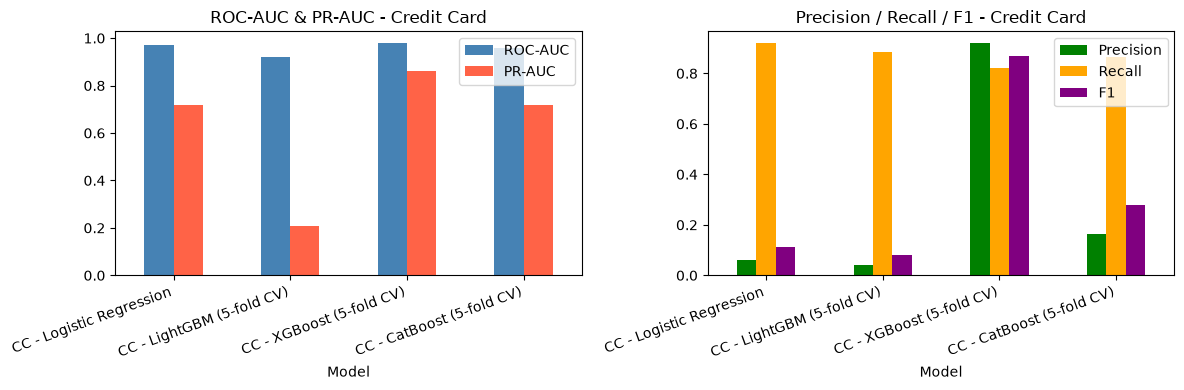

In [102]:
cc_results = [r for r in results_table if r["Model"].startswith("CC")]
df_cc_res = pd.DataFrame(cc_results).set_index("Model")
print("\n📊 Kết quả Credit Card Fraud Detection:")
display(df_cc_res)

# Biểu đồ so sánh ROC-AUC và PR-AUC
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_cc_res[["ROC-AUC", "PR-AUC"]].plot(
    kind="bar", ax=axes[0], color=["steelblue", "tomato"]
)
axes[0].set_title("ROC-AUC & PR-AUC - Credit Card")
axes[0].set_xticklabels(df_cc_res.index, rotation=20, ha="right")
axes[0].legend()
df_cc_res[["Precision", "Recall", "F1"]].plot(
    kind="bar", ax=axes[1], color=["green", "orange", "purple"]
)
axes[1].set_title("Precision / Recall / F1 - Credit Card")
axes[1].set_xticklabels(df_cc_res.index, rotation=20, ha="right")
axes[1].legend()
plt.tight_layout()
plt.show()


---
# PHẦN 2: IEEE-CIS Fraud Detection

Dataset của cuộc thi Kaggle do IEEE Computational Intelligence Society tổ chức.
- **Nguồn:** [Kaggle Competition: ieee-fraud-detection](https://www.kaggle.com/c/ieee-fraud-detection)
- **Kích thước:** 590,540 giao dịch, 2 bảng (transaction + identity)
- **Features:** 400+ features đa dạng (C, D, V, M columns, device info, ...)
- **Target:** `isFraud` (0/1)
- **Thách thức:** Feature engineering phức tạp, merge 2 bảng, dữ liệu nhiều missing values

## 2.1 Giới Thiệu Dataset

Dataset gồm 2 file cần merge:
- **train_transaction.csv**: Thông tin giao dịch (amount, card info, address, email domain, ...)
- **train_identity.csv**: Thông tin thiết bị và mạng (device type, browser, OS, ...)

**Cột thời gian:** `TransactionDT` là giây kể từ thời điểm tham chiếu `2017-11-30`.

## 2.2 Load Dữ Liệu

Tải dataset competition từ Kaggle qua `kagglehub`.

> **Lưu ý:** Cần accept Terms of Competition trên Kaggle trước khi tải về được.

In [103]:
print("📥 Đang tải dataset IEEE-CIS Fraud Detection...")
ieee_path = kagglehub.competition_download("ieee-fraud-detection")
print(f"✅ Dataset tải về tại: {ieee_path}")

ieee_files = glob.glob(os.path.join(ieee_path, "**", "*.csv"), recursive=True)
print("Files tìm thấy:")
for f in sorted(ieee_files):
    size_mb = os.path.getsize(f) / 1024**2
    print(f"  {os.path.basename(f):40s} {size_mb:.1f} MB")


📥 Đang tải dataset IEEE-CIS Fraud Detection...
✅ Dataset tải về tại: C:\Users\Thaibh\.cache\kagglehub\competitions\ieee-fraud-detection
Files tìm thấy:
  sample_submission.csv                    5.8 MB
  test_identity.csv                        24.6 MB
  test_transaction.csv                     584.8 MB
  train_identity.csv                       25.3 MB
  train_transaction.csv                    651.7 MB


In [104]:
# Xác định đúng file
trans_file = [f for f in ieee_files if "train_transaction" in f][0]
ident_file = [f for f in ieee_files if "train_identity" in f][0]

print(f"Transaction file: {trans_file}")
print(f"Identity file:    {ident_file}")

print("\n📖 Đang đọc train_transaction.csv...")
train_trans = pd.read_csv(trans_file)
print(f"train_transaction shape: {train_trans.shape}")

print("\n📖 Đang đọc train_identity.csv...")
train_ident = pd.read_csv(ident_file)
print(f"train_identity shape: {train_ident.shape}")


Transaction file: C:\Users\Thaibh\.cache\kagglehub\competitions\ieee-fraud-detection\train_transaction.csv
Identity file:    C:\Users\Thaibh\.cache\kagglehub\competitions\ieee-fraud-detection\train_identity.csv

📖 Đang đọc train_transaction.csv...
train_transaction shape: (590540, 394)

📖 Đang đọc train_identity.csv...
train_identity shape: (144233, 41)


## 2.3 Preprocessing

### Các bước xử lý:
1. **Merge** transaction + identity theo `TransactionID` (LEFT JOIN)
2. **Chuyển đổi thời gian:** `TransactionDT` → datetime → tháng
3. **Tối ưu bộ nhớ:** float64 → float32
4. **Train/Test split theo tháng:** tránh data leakage từ thời gian

In [105]:
from datetime import datetime, timedelta

# Merge transaction và identity
print("🔀 Merging transaction + identity...")
df_ieee = train_trans.merge(train_ident, on="TransactionID", how="left")
print(f"Merged shape: {df_ieee.shape}")

# Chuyển đổi thời gian
START_DATE = datetime.strptime("2017-11-30", "%Y-%m-%d")
df_ieee["DT"] = df_ieee["TransactionDT"].apply(
    lambda x: START_DATE + timedelta(seconds=x)
)
df_ieee["DT_M"] = (df_ieee["DT"].dt.year - 2017) * 12 + df_ieee["DT"].dt.month
print(f"\nPhân phối tháng:")
print(df_ieee["DT_M"].value_counts().sort_index())

# Tối ưu bộ nhớ: float64 -> float32
float64_cols = df_ieee.select_dtypes(include="float64").columns
df_ieee[float64_cols] = df_ieee[float64_cols].astype("float32")
print(f"\nĐã chuyển {len(float64_cols)} cột float64 → float32")
print(f"Phân phối isFraud: {df_ieee['isFraud'].value_counts().to_dict()}")


🔀 Merging transaction + identity...
Merged shape: (590540, 434)

Phân phối tháng:
DT_M
12    137321
13     92585
14     86021
15    101632
16     83655
17     89326
Name: count, dtype: int64

Đã chuyển 399 cột float64 → float32
Phân phối isFraud: {0: 569877, 1: 20663}


In [106]:
# Train/Test split theo tháng (tránh data leakage)
last_month = df_ieee["DT_M"].max()
print(f"Tháng cuối: {last_month}")
print(f"Train: tháng < {last_month}, Test: tháng = {last_month}")

train_mask = df_ieee["DT_M"] < last_month
test_mask = df_ieee["DT_M"] == last_month

TARGET = "isFraud"
IGNORE = ["TransactionID", "TransactionDT", "DT", "DT_M", TARGET]

X_ieee_train = df_ieee[train_mask].drop(columns=IGNORE, errors="ignore")
y_ieee_train = df_ieee[train_mask][TARGET]
X_ieee_test = df_ieee[test_mask].drop(columns=IGNORE, errors="ignore")
y_ieee_test = df_ieee[test_mask][TARGET]

print(f"\nTrain: {X_ieee_train.shape}, fraud rate: {y_ieee_train.mean():.4f}")
print(f"Test:  {X_ieee_test.shape}, fraud rate:  {y_ieee_test.mean():.4f}")


Tháng cuối: 17
Train: tháng < 17, Test: tháng = 17

Train: (501214, 431), fraud rate: 0.0350
Test:  (89326, 431), fraud rate:  0.0349


## 2.4 Baseline: LightGBM Không Feature Engineering

Model đầu tiên chỉ dùng raw features (sau khi xử lý categorical bằng LightGBM native).
LightGBM có thể xử lý categorical features và missing values tự động.

In [107]:
# Encode categorical columns cho LightGBM
cat_cols = X_ieee_train.select_dtypes(include="object").columns.tolist()
print(f"Categorical columns ({len(cat_cols)}): {cat_cols[:10]}...")

X_tr2 = X_ieee_train.copy()
X_te2 = X_ieee_test.copy()

for col in cat_cols:
    X_tr2[col] = X_tr2[col].astype("category")
    X_te2[col] = X_te2[col].astype("category")

print(f"Features: {X_tr2.shape[1]}")


Categorical columns (31): ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5']...
Features: 431


In [108]:
print("🌳 Training LightGBM Baseline (IEEE-CIS)...")

ieee_lgb_params = {
    "objective": "binary",
    "metric": "auc",
    "n_estimators": 1000,
    "learning_rate": 0.05,
    "num_leaves": 256,
    "min_child_samples": 20,
    "scale_pos_weight": int((y_ieee_train == 0).sum() / (y_ieee_train == 1).sum()),
    "random_state": 42,
    "verbose": -1,
}

ieee_lgb_base = lgb.LGBMClassifier(**ieee_lgb_params)
ieee_lgb_base.fit(
    X_tr2,
    y_ieee_train,
    eval_set=[(X_te2, y_ieee_test)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)],
)

proba_base = ieee_lgb_base.predict_proba(X_te2)[:, 1]
res = benchmark("IEEE - LightGBM Baseline (No FE)", y_ieee_test, proba_base)
results_table.append(res)


🌳 Training LightGBM Baseline (IEEE-CIS)...
[100]	valid_0's auc: 0.919901

Model: IEEE - LightGBM Baseline (No FE)
  Accuracy    : 0.9333
  Precision   : 0.3019
  Recall      : 0.6962
  F1          : 0.4212
  ROC-AUC     : 0.9209
  PR-AUC      : 0.5536
  Confusion Matrix:
[[81200  5012]
 [  946  2168]]


## 2.5 LightGBM Với Feature Engineering Nâng Cao

Feature engineering là chìa khóa quan trọng để cải thiện hiệu suất trên IEEE-CIS dataset.

### Các loại features được tạo:
1. **Time features:** Giờ, ngày trong tuần, ngày trong tháng từ TransactionDT
2. **UID (User Identifier):** Kết hợp các cột để tạo unique user ID
3. **Frequency Encoding:** Mã hóa tần suất cho categorical features
4. **D columns normalization:** Chuẩn hóa các cột D theo uid
5. **Aggregation features:** Thống kê group-by theo uid
6. **Identity parsing:** Trích xuất thông tin từ DeviceInfo, id_30, id_31

In [109]:
# ─── Helper Functions cho Feature Engineering ───────────────────────────────


def freq(df, col, name=None):
    """Frequency encoding: đếm tần suất xuất hiện của từng giá trị."""
    if name is None:
        name = col + "_freq"
    freq_map = df[col].value_counts(dropna=False)
    df[name] = df[col].map(freq_map).astype("float32")
    return df


def group_agg(df, group_col, agg_col, agg_func="mean", name=None):
    """Tính giá trị thống kê của agg_col theo group_col."""
    if name is None:
        name = f"{group_col}_{agg_col}_{agg_func}"
    agg_map = df.groupby(group_col)[agg_col].agg(agg_func)
    df[name] = df[group_col].map(agg_map).astype("float32")
    return df


def normalize(df, col, group_col, name=None):
    """Chuẩn hóa col theo group_col (z-score within group)."""
    if name is None:
        name = f"{col}_norm_by_{group_col}"
    group_mean = df.groupby(group_col)[col].transform("mean")
    group_std = df.groupby(group_col)[col].transform("std").fillna(1)
    df[name] = ((df[col] - group_mean) / group_std).astype("float32")
    return df


print("✅ Helper functions defined: freq(), group_agg(), normalize()")


✅ Helper functions defined: freq(), group_agg(), normalize()


In [110]:
def feature_engineering_ieee(df_in):
    """Pipeline feature engineering đầy đủ cho IEEE-CIS dataset."""
    df = df_in.copy()

    # 1. Time features
    START_DATE = datetime.strptime("2017-11-30", "%Y-%m-%d")
    df["DT"] = df["TransactionDT"].apply(lambda x: START_DATE + timedelta(seconds=x))
    df["DT_M"] = ((df["DT"].dt.year - 2017) * 12 + df["DT"].dt.month).astype("int8")
    df["DT_W"] = df["DT"].dt.dayofweek.astype("int8")  # 0=Mon, 6=Sun
    df["DT_D"] = df["DT"].dt.day.astype("int8")
    df["DT_H"] = df["DT"].dt.hour.astype("int8")
    df["DT_Wd"] = df["DT"].dt.weekday.astype("int8")  # alias
    df.drop(columns=["DT"], inplace=True)
    print("  ✓ Time features done")

    # 2. UID - kết hợp các cột đặc trưng user
    df["uid"] = df["card1"].astype(str) + "_" + df["card2"].astype(str)
    df["uid2"] = (
        df["uid"] + "_" + df["card3"].astype(str) + "_" + df["card5"].astype(str)
    )
    df["uid3"] = (
        df["uid2"] + "_" + df["addr1"].astype(str) + "_" + df["addr2"].astype(str)
    )
    df["uid4"] = df["uid3"] + "_" + df["P_emaildomain"].astype(str)
    df["uid5"] = df["uid4"] + "_" + df["R_emaildomain"].astype(str)
    print("  ✓ UID features done")

    # 3. Frequency encoding
    freq_cols = [
        "card1",
        "card2",
        "card3",
        "card4",
        "card5",
        "card6",
        "addr1",
        "addr2",
        "P_emaildomain",
        "R_emaildomain",
        "uid",
        "uid2",
        "uid3",
        "uid4",
        "uid5",
    ]
    for col in freq_cols:
        df = freq(df, col)
    print("  ✓ Frequency encoding done")

    # 4. D columns - normalize bằng TransactionDT
    # D1-D15: số ngày kể từ giao dịch trước (theo user)
    for i in range(1, 16):
        col = f"D{i}"
        if col in df.columns:
            df[f"{col}_norm"] = (df[col] - df["TransactionDT"] / (24 * 60 * 60)).astype(
                "float32"
            )
    print("  ✓ D columns normalization done")

    # 5. Aggregation: TransactionAmt theo uid
    for uid_col in ["uid", "uid2", "uid3"]:
        df = group_agg(df, uid_col, "TransactionAmt", "mean")
        df = group_agg(df, uid_col, "TransactionAmt", "std")
        df = group_agg(df, uid_col, "TransactionAmt", "min")
        df = group_agg(df, uid_col, "TransactionAmt", "max")
    print("  ✓ Aggregation features done")

    # 6. Normalize TransactionAmt by uid
    for uid_col in ["uid", "uid2"]:
        df = normalize(df, "TransactionAmt", uid_col)
    print("  ✓ Normalization done")

    # 7. Identity parsing
    if "DeviceInfo" in df.columns:
        df["device_name"] = df["DeviceInfo"].str.split("/", expand=True)[0].str.lower()
        df["device_version"] = (
            df["DeviceInfo"].str.split("/", expand=True)[1].fillna("")
        )
    if "id_30" in df.columns:
        df["OS_id_30"] = df["id_30"].str.split(" ", expand=True)[0].str.lower()
        df["ver_id_30"] = df["id_30"].str.split(" ", expand=True)[1].fillna("")
    if "id_31" in df.columns:
        df["browser_id_31"] = df["id_31"].str.split(" ", expand=True)[0].str.lower()
        df["ver_id_31"] = df["id_31"].str.split(" ", expand=True)[1].fillna("")
    print("  ✓ Identity parsing done")

    return df


print("✅ Feature engineering function defined.")


✅ Feature engineering function defined.


In [111]:
print("⚙️  Applying feature engineering...")

# Merge lại trước khi FE (cần TransactionDT)
df_ieee_fe_full = train_trans.merge(train_ident, on="TransactionID", how="left")

# Apply FE
df_ieee_fe = feature_engineering_ieee(df_ieee_fe_full)

# Tính lại DT_M sau FE (DT_M vẫn còn sau FE)
IGNORE_FE = ["TransactionID", "TransactionDT", "isFraud"]

last_month_fe = df_ieee_fe["DT_M"].max()
train_mask_fe = df_ieee_fe["DT_M"] < last_month_fe
test_mask_fe = df_ieee_fe["DT_M"] == last_month_fe

# Encode categorical
cat_cols_fe = df_ieee_fe.select_dtypes(include="object").columns.tolist()
for col in cat_cols_fe:
    df_ieee_fe[col] = df_ieee_fe[col].astype("category")

drop_cols_fe = [c for c in IGNORE_FE if c in df_ieee_fe.columns]
X_fe_train = df_ieee_fe[train_mask_fe].drop(columns=drop_cols_fe)
y_fe_train = df_ieee_fe[train_mask_fe]["isFraud"]
X_fe_test = df_ieee_fe[test_mask_fe].drop(columns=drop_cols_fe)
y_fe_test = df_ieee_fe[test_mask_fe]["isFraud"]

print(f"\nSau Feature Engineering:")
print(f"  Train: {X_fe_train.shape}")
print(f"  Test:  {X_fe_test.shape}")
print(f"  Số features mới: {X_fe_train.shape[1] - X_tr2.shape[1]}")


⚙️  Applying feature engineering...
  ✓ Time features done
  ✓ UID features done
  ✓ Frequency encoding done
  ✓ D columns normalization done
  ✓ Aggregation features done
  ✓ Normalization done
  ✓ Identity parsing done

Sau Feature Engineering:
  Train: (501214, 491)
  Test:  (89326, 491)
  Số features mới: 60


In [112]:
print("🌳 Training LightGBM với Full Feature Engineering...")

ieee_fe_lgb = lgb.LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=256,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.5,
    scale_pos_weight=int((y_fe_train == 0).sum() / (y_fe_train == 1).sum()),
    random_state=42,
    verbose=-1,
)

ieee_fe_lgb.fit(
    X_fe_train,
    y_fe_train,
    eval_set=[(X_fe_test, y_fe_test)],
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)],
)

proba_fe = ieee_fe_lgb.predict_proba(X_fe_test)[:, 1]
res = benchmark("IEEE - LightGBM + Feature Engineering", y_fe_test, proba_fe)
results_table.append(res)


🌳 Training LightGBM với Full Feature Engineering...
[200]	valid_0's auc: 0.91063
[400]	valid_0's auc: 0.913607
[600]	valid_0's auc: 0.917295
[800]	valid_0's auc: 0.919899
[1000]	valid_0's auc: 0.920785
[1200]	valid_0's auc: 0.921861
[1400]	valid_0's auc: 0.922323

Model: IEEE - LightGBM + Feature Engineering
  Accuracy    : 0.9804
  Precision   : 0.8722
  Recall      : 0.5128
  F1          : 0.6459
  ROC-AUC     : 0.9225
  PR-AUC      : 0.6673
  Confusion Matrix:
[[85978   234]
 [ 1517  1597]]


## 2.6 Mô Hình XGBoost Với Feature Engineering

Huấn luyện thêm mô hình **XGBoost (Extreme Gradient Boosting)** trên toàn bộ tập đặc trưng nâng cao của IEEE-CIS để so sánh hiệu năng với LightGBM:
- Sử dụng thuật toán biểu đồ `tree_method="hist"` và `enable_categorical=True` giúp xử lý nhanh dữ liệu lớn chứa các biến định danh/phân loại.
- Tinh chỉnh tham số mất cân bằng: `scale_pos_weight`.
- Áp dụng `early_stopping_rounds=100` trên tập kiểm thử (tháng cuối) để tránh quá khớp (overfitting).


In [114]:
X_fe_train

,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,...,uid3_TransactionAmt_min,uid3_TransactionAmt_max,TransactionAmt_norm_by_uid,TransactionAmt_norm_by_uid2,device_name,device_version,OS_id_30,ver_id_30,browser_id_31,ver_id_31
0,68.500,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,...,NaN,NaN,NaN,NaN,NaN,,NaN,,NaN,
1,29.000,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,...,29.0,4592.020020,-0.446046,-0.446046,NaN,,NaN,,NaN,
2,59.000,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,...,25.0,122.989998,-0.378888,-0.378888,NaN,,NaN,,NaN,
3,50.000,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,...,6.0,3190.000000,-0.380363,-0.380363,NaN,,NaN,,NaN,
4,50.000,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,...,50.0,50.000000,-0.829466,-0.829466,samsung sm-g892a build,NRD90M,android,7.0,samsung,browser
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501209,554.000,W,11636,457.0,150.0,visa,226.0,debit,299.0,87.0,...,19.5,1009.950012,2.746389,2.746389,NaN,,NaN,,NaN,
501210,39.000,W,17400,174.0,150.0,visa,226.0,debit,123.0,87.0,...,10.0,2134.949951,-0.459197,-0.459197,NaN,,NaN,,NaN,
501211,29.000,W,9500,321.0,150.0,visa,226.0,debit,204.0,87.0,...,5.0,2943.050049,-0.447504,-0.447504,NaN,,NaN,,NaN,
501212,112.000,W,16255,470.0,150.0,mastercard,137.0,credit,126.0,87.0,...,29.0,664.000000,-0.108261,-0.108261,NaN,,NaN,,NaN,


In [115]:
num_cols = X_fe_train.select_dtypes(include=[np.number]).columns
# 1. Đổi inf -> NaN cho cả train và test
X_fe_train[num_cols] = X_fe_train[num_cols].replace([np.inf, -np.inf], np.nan)
X_fe_test[num_cols] = X_fe_test[num_cols].replace([np.inf, -np.inf], np.nan)

In [116]:
import xgboost as xgb

print("🚀 Training XGBoost với Full Feature Engineering (IEEE-CIS)...")

# Tính toán tỷ lệ mất cân bằng class cho XGBoost
scale_pos_weight_xgb = (y_fe_train == 0).sum() / (y_fe_train == 1).sum()

ieee_xgb = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    n_estimators=1500,
    learning_rate=0.05,
    max_depth=9,
    subsample=0.8,
    colsample_bytree=0.5,
    scale_pos_weight=scale_pos_weight_xgb,
    tree_method="hist",
    enable_categorical=True,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=100,
)

ieee_xgb.fit(X_fe_train, y_fe_train, eval_set=[(X_fe_test, y_fe_test)], verbose=200)

proba_xgb = ieee_xgb.predict_proba(X_fe_test)[:, 1]
res_xgb = benchmark("IEEE - XGBoost + Feature Engineering", y_fe_test, proba_xgb)
results_table.append(res_xgb)


🚀 Training XGBoost với Full Feature Engineering (IEEE-CIS)...
[0]	validation_0-auc:0.79238
[173]	validation_0-auc:0.90482

Model: IEEE - XGBoost + Feature Engineering
  Accuracy    : 0.9413
  Precision   : 0.3311
  Recall      : 0.6686
  F1          : 0.4428
  ROC-AUC     : 0.9092
  PR-AUC      : 0.5496
  Confusion Matrix:
[[82005  4207]
 [ 1032  2082]]


## 2.7 Kết Quả Benchmark - IEEE-CIS

So sánh hiệu năng giữa LightGBM baseline, LightGBM + Feature Engineering và XGBoost + Feature Engineering.



📊 Kết quả IEEE-CIS Fraud Detection:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
IEEE - LightGBM Baseline (No FE),0.9333,0.3019,0.6962,0.4212,0.9209,0.5536
IEEE - LightGBM + Feature Engineering,0.9804,0.8722,0.5128,0.6459,0.9225,0.6673
IEEE - XGBoost + Feature Engineering,0.9413,0.3311,0.6686,0.4428,0.9092,0.5496


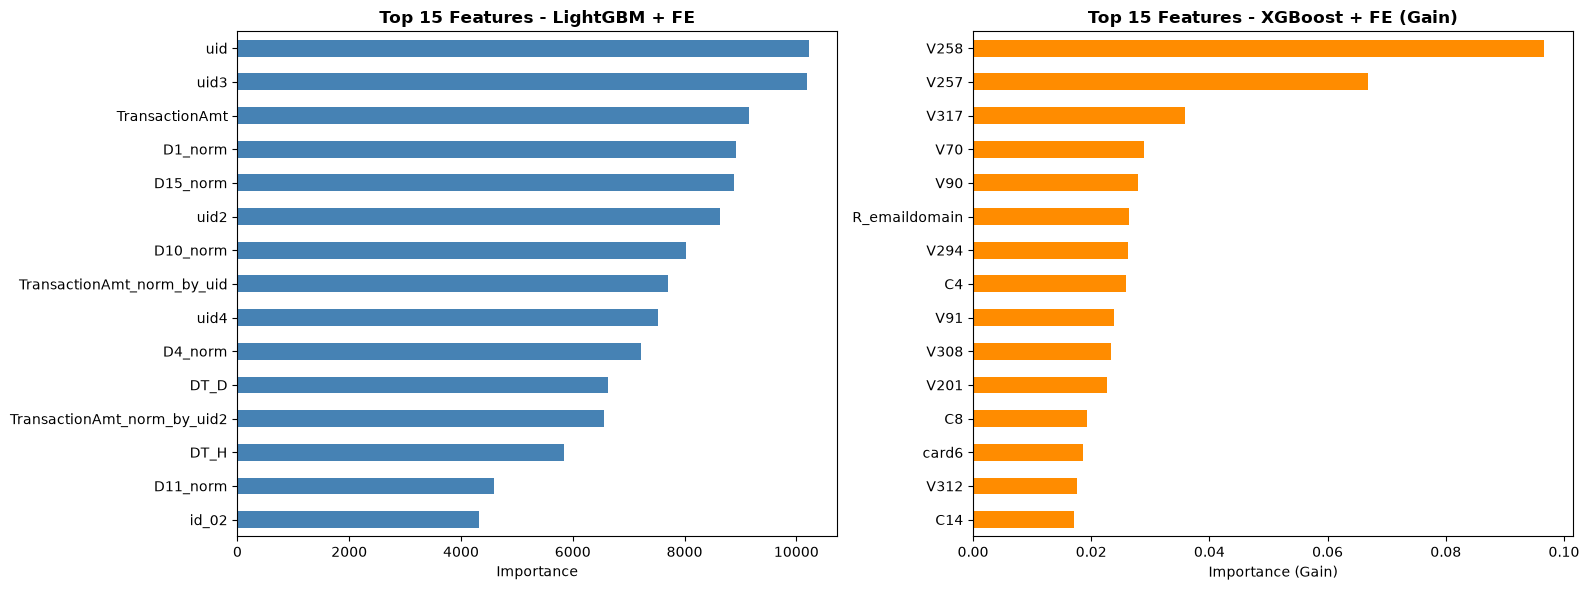

In [117]:
ieee_results = [r for r in results_table if r["Model"].startswith("IEEE")]
df_ieee_res = pd.DataFrame(ieee_results).set_index("Model")
print("\n📊 Kết quả IEEE-CIS Fraud Detection:")
display(df_ieee_res)

# So sánh Top 15 Feature Importances giữa LightGBM và XGBoost
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fi_lgb = pd.Series(ieee_fe_lgb.feature_importances_, index=X_fe_train.columns).nlargest(
    15
)
fi_lgb.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Top 15 Features - LightGBM + FE", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Importance")
axes[0].invert_yaxis()

fi_xgb = pd.Series(ieee_xgb.feature_importances_, index=X_fe_train.columns).nlargest(15)
fi_xgb.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title(
    "Top 15 Features - XGBoost + FE (Gain)", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Importance (Gain)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


---
# PHẦN 3: PaySim Fraud Detection

Dataset mô phỏng (synthetic) giao dịch thanh toán mobile money.
- **Nguồn:** Kaggle - [ealaxi/paysim1](https://www.kaggle.com/datasets/ealaxi/paysim1)
- **Kích thước:** ~6.3 triệu giao dịch (thu nhỏ 1/4 từ tập dữ liệu gốc)
- **Loại giao dịch:** CASH-IN, CASH-OUT, DEBIT, PAYMENT, TRANSFER
- **Thực tế:** Gian lận chỉ xảy ra ở CASH_OUT và TRANSFER
- **Target:** `isFraud` (0/1)


## 3.1 Giới Thiệu Dataset

PaySim là dataset tổng hợp được tạo ra dựa trên dữ liệu thực từ dịch vụ mobile money tại Châu Phi.

> [!IMPORTANT]
> **LƯU Ý ĐẶC BIỆT TỪ TÁC GIẢ KAGGLE (Kaggle Dataset Note):**
> *"This synthetic dataset is scaled down 1/4 of the original dataset and it is created just for Kaggle.*\
> *NOTE: Transactions which are detected as fraud are cancelled, so for fraud detection these columns (`oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`) must not be used."*
>
> **Giải thích nguyên nhân:**
> Trong mô phỏng PaySim, các giao dịch bị phát hiện là gian lận đều bị **hủy bỏ (cancelled)** ngay lập tức. Do đó, số dư tài khoản người gửi không bị trừ và người nhận không được cộng tiền bình thường (hoặc số dư bằng 0 một cách bất thường). Nếu đưa 4 cột số dư này vào mô hình sẽ dẫn đến **Data Leakage (Rò rỉ nhãn)** nghiêm trọng, mô hình đạt độ chính xác ảo ~99.9% chỉ nhờ học được dấu vết hủy giao dịch chứ không học được hành vi gian lận thực sự.

**Các cột hợp lệ được phép sử dụng:**
- `step`: Đơn vị thời gian (1 step = 1 giờ, tổng 744 steps = 30 ngày)
- `type`: Loại giao dịch (CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER)
- `amount`: Số tiền giao dịch
- `nameOrig`: Mã định danh khách hàng khởi tạo giao dịch
- `nameDest`: Mã định danh người nhận tiền

**Các cột bị loại bỏ hoàn toàn:**
- `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`: Tuyệt đối không dùng do rò rỉ dữ liệu (cancellation artifact).
- `isFlaggedFraud`: Flag thủ công theo ngưỡng (> 200.000) không dùng làm feature.


## 3.2 Load Dữ Liệu

In [118]:
print("📥 Đang tải dataset PaySim...")
paysim_path = kagglehub.dataset_download("ealaxi/paysim1")
print(f"✅ Dataset tải về tại: {paysim_path}")

ps_files = glob.glob(os.path.join(paysim_path, "**", "*.csv"), recursive=True)
print(f"Files CSV: {ps_files}")
ps_csv = ps_files[0]

print(f"\n📖 Đang đọc {os.path.basename(ps_csv)}...")
df_ps = pd.read_csv(ps_csv)
print(f"Shape: {df_ps.shape}")
print(f"Columns: {list(df_ps.columns)}")
df_ps.head(3)


📥 Đang tải dataset PaySim...
✅ Dataset tải về tại: C:\Users\Thaibh\.cache\kagglehub\datasets\ealaxi\paysim1\versions\2
Files CSV: ['C:\\Users\\Thaibh\\.cache\\kagglehub\\datasets\\ealaxi\\paysim1\\versions\\2\\PS_20174392719_1491204439457_log.csv']

📖 Đang đọc PS_20174392719_1491204439457_log.csv...
Shape: (6362620, 11)
Columns: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0


## 3.3 EDA & Preprocessing (Tuân Thủ Quy Tắc No-Balance)

Phân tích và kỹ thuật đặc trưng (Feature Engineering) hoàn toàn **không dựa vào các cột số dư**:
1. **Đặc trưng thời gian từ `step`:**
   - `hour = step % 24`: Giờ trong ngày (hành vi gian lận thường tập trung vào đêm/sáng sớm)
   - `day = (step // 24) % 7`: Ngày trong tuần
2. **Biến đổi số tiền:**
   - `amount_log = log1p(amount)`: Chuẩn hóa phân phối lệch phải của số tiền
   - `amount_to_type_mean`: Tỷ số giữa số tiền giao dịch so với mức trung bình của loại giao dịch đó
3. **Đặc trưng từ tài khoản người gửi & nhận (`nameOrig`, `nameDest`):**
   - `is_merchant_dest`: Người nhận có phải là Merchant hay Customer (bắt đầu bằng 'M')
   - `dest_count`: Tần suất xuất hiện tài khoản nhận (kẻ gian lận thường chuyển đến cùng một số tài khoản gom tiền)
   - `orig_count`: Tần suất xuất hiện tài khoản gửi
4. **One-Hot Encoding** cho cột `type`.


In [119]:
print("=== Phân phối loại giao dịch ===")
print(df_ps["type"].value_counts())

print("\n=== Phân phối isFraud theo type ===")
print(
    df_ps.groupby("type")["isFraud"]
    .agg(["sum", "mean"])
    .rename(columns={"sum": "Fraud Count", "mean": "Fraud Rate"})
)

print(f"\nTổng fraud: {df_ps['isFraud'].sum():,} / {len(df_ps):,}")
print(f"Tỷ lệ fraud: {df_ps['isFraud'].mean() * 100:.4f}%")


=== Phân phối loại giao dịch ===
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

=== Phân phối isFraud theo type ===
          Fraud Count  Fraud Rate
type                             
CASH_IN             0    0.000000
CASH_OUT         4116    0.001840
DEBIT               0    0.000000
PAYMENT             0    0.000000
TRANSFER         4097    0.007688

Tổng fraud: 8,213 / 6,362,620
Tỷ lệ fraud: 0.1291%


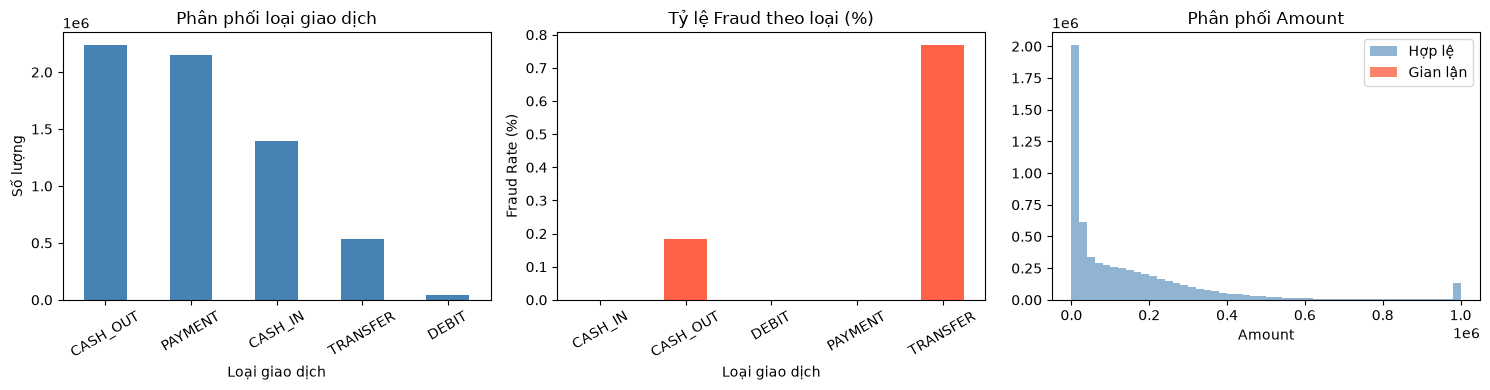

In [120]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Transaction type distribution
df_ps["type"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Phân phối loại giao dịch")
axes[0].set_xlabel("Loại giao dịch")
axes[0].set_ylabel("Số lượng")
axes[0].tick_params(axis="x", rotation=30)

# Fraud by type
fraud_by_type = df_ps.groupby("type")["isFraud"].mean() * 100
fraud_by_type.plot(kind="bar", ax=axes[1], color="tomato")
axes[1].set_title("Tỷ lệ Fraud theo loại (%)")
axes[1].set_xlabel("Loại giao dịch")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].tick_params(axis="x", rotation=30)

# Amount distribution by fraud
axes[2].hist(
    df_ps[df_ps["isFraud"] == 0]["amount"].clip(0, 1e6),
    bins=50,
    alpha=0.6,
    label="Hợp lệ",
    color="steelblue",
)
axes[2].hist(
    df_ps[df_ps["isFraud"] == 1]["amount"].clip(0, 1e6),
    bins=50,
    alpha=0.8,
    label="Gian lận",
    color="tomato",
)
axes[2].set_title("Phân phối Amount")
axes[2].set_xlabel("Amount")
axes[2].legend()

plt.tight_layout()
plt.show()


In [121]:
# Preprocessing PaySim - TUÂN THỦ QUY TẮC KAGGLE: LOẠI BỎ TOÀN BỘ CỘT SỐ DƯ
print("⚙️  Preprocessing PaySim theo quy định Kaggle (No Balance Columns)...")

# 1. Bỏ 4 cột số dư (tránh data leakage) và cột isFlaggedFraud
forbidden_cols = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "isFlaggedFraud",
]
df_ps_clean = df_ps.drop(columns=forbidden_cols)

# 2. Feature Engineering hợp lệ
# Thời gian trong ngày và trong tuần
df_ps_clean["hour"] = (df_ps_clean["step"] % 24).astype("int8")
df_ps_clean["day"] = ((df_ps_clean["step"] // 24) % 7).astype("int8")

# Log transform số tiền
df_ps_clean["amount_log"] = np.log1p(df_ps_clean["amount"]).astype("float32")

# Loại người nhận (Merchant hay Customer)
df_ps_clean["is_merchant_dest"] = (
    df_ps_clean["nameDest"].str.startswith("M").astype("int8")
)

# Tần suất xuất hiện tài khoản nhận và gửi (Frequency encoding)
dest_freq = df_ps_clean["nameDest"].value_counts()
df_ps_clean["dest_count"] = df_ps_clean["nameDest"].map(dest_freq).astype("int32")

orig_freq = df_ps_clean["nameOrig"].value_counts()
df_ps_clean["orig_count"] = df_ps_clean["nameOrig"].map(orig_freq).astype("int32")

# Tỷ số giữa số tiền giao dịch so với trung bình của loại giao dịch đó
type_mean_amt = df_ps_clean.groupby("type")["amount"].transform("mean")
df_ps_clean["amount_to_type_mean"] = (
    df_ps_clean["amount"] / (type_mean_amt + 1e-5)
).astype("float32")

# Loại bỏ các cột ID chuỗi gốc sau khi đã trích xuất đặc trưng
df_ps_clean = df_ps_clean.drop(columns=["nameOrig", "nameDest"])

# One-hot encoding cột 'type'
type_dummies = pd.get_dummies(df_ps_clean["type"], prefix="type", dtype="int8")
df_ps_proc = pd.concat([df_ps_clean.drop(columns=["type"]), type_dummies], axis=1)

print(f"Processed shape: {df_ps_proc.shape}")
print(f"Số lượng features sử dụng: {len(df_ps_proc.columns) - 1}")
for col in df_ps_proc.columns:
    if col != "isFraud":
        print(f"  - {col}")


⚙️  Preprocessing PaySim theo quy định Kaggle (No Balance Columns)...
Processed shape: (6362620, 15)
Số lượng features sử dụng: 14
  - step
  - amount
  - hour
  - day
  - amount_log
  - is_merchant_dest
  - dest_count
  - orig_count
  - amount_to_type_mean
  - type_CASH_IN
  - type_CASH_OUT
  - type_DEBIT
  - type_PAYMENT
  - type_TRANSFER


In [122]:
# Train/Test split
X_ps = df_ps_proc.drop(columns=["isFraud"])
y_ps = df_ps_proc["isFraud"]

X_train_ps, X_test_ps, y_train_ps, y_test_ps = train_test_split(
    X_ps, y_ps, test_size=0.2, random_state=42, stratify=y_ps
)

print(f"Train: {X_train_ps.shape}, fraud rate: {y_train_ps.mean():.4f}")
print(f"Test:  {X_test_ps.shape}, fraud rate:  {y_test_ps.mean():.4f}")


Train: (5090096, 14), fraud rate: 0.0013
Test:  (1272524, 14), fraud rate:  0.0013


## 3.4 Mô Hình LightGBM

Với PaySim, do dữ liệu rất lớn (~5M train rows) nên dùng LightGBM một lần thay vì CV.
Sử dụng early stopping trên validation set.

In [123]:
print("🌳 Training LightGBM (PaySim)...")

ps_lgb = lgb.LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=100,
    scale_pos_weight=int((y_train_ps == 0).sum() / (y_train_ps == 1).sum()),
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)

ps_lgb.fit(
    X_train_ps,
    y_train_ps,
    eval_set=[(X_test_ps, y_test_ps)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)],
)

proba_ps = ps_lgb.predict_proba(X_test_ps)[:, 1]
res = benchmark("PaySim - LightGBM", y_test_ps, proba_ps)
results_table.append(res)


🌳 Training LightGBM (PaySim)...

Model: PaySim - LightGBM
  Accuracy    : 0.8082
  Precision   : 0.0064
  Recall      : 0.9574
  F1          : 0.0127
  ROC-AUC     : 0.9728
  PR-AUC      : 0.0851
  Confusion Matrix:
[[1026914  243967]
 [     70    1573]]


## 3.5 Kết Quả Benchmark - PaySim

Phân tích feature importance và kết quả mô hình PaySim.

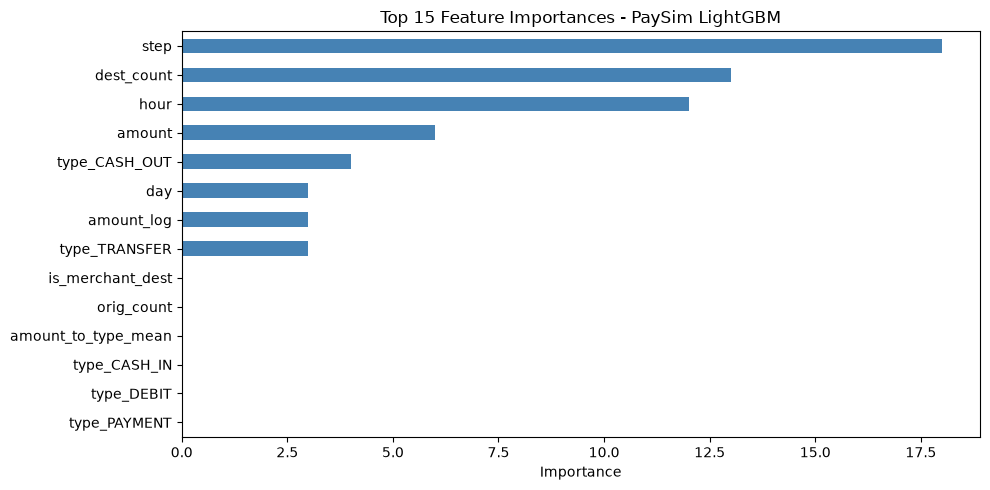

In [124]:
ps_fi = pd.Series(ps_lgb.feature_importances_, index=X_train_ps.columns)
top15_ps = ps_fi.nlargest(15)

plt.figure(figsize=(10, 5))
top15_ps.plot(kind="barh", color="steelblue")
plt.title("Top 15 Feature Importances - PaySim LightGBM")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


---
# 🏆 Tổng Kết So Sánh Tất Cả Mô Hình

Bảng tổng hợp kết quả của toàn bộ các mô hình đã huấn luyện trên 3 dataset.

**Lưu ý về chỉ số đánh giá:**
- **ROC-AUC:** Đo khả năng phân biệt fraud vs non-fraud (cao hơn tốt hơn)
- **PR-AUC:** Phù hợp hơn với dữ liệu imbalanced (cao hơn tốt hơn)
- **F1:** Trung bình điều hòa Precision và Recall
- **Recall:** Quan trọng nhất trong fraud detection - không bỏ sót fraud

In [125]:
# Tổng hợp kết quả tất cả models
df_all_results = pd.DataFrame(results_table)
df_all_results = df_all_results.set_index("Model")

print("\n" + "=" * 70)
print("📊 BẢNG TỔNG HỢP KẾT QUẢ TẤT CẢ MÔ HÌNH")
print("=" * 70)
display(
    df_all_results.style.background_gradient(
        subset=["ROC-AUC", "PR-AUC", "F1", "Recall"], cmap="RdYlGn"
    ).format(
        "{:.4f}", subset=["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
    )
)



📊 BẢNG TỔNG HỢP KẾT QUẢ TẤT CẢ MÔ HÌNH


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
CC - Logistic Regression,0.9755,0.0609,0.9184,0.1141,0.9722,0.7189
CC - LightGBM (5-fold CV),0.9656,0.0428,0.8841,0.0816,0.9217,0.2068
CC - XGBoost (5-fold CV),0.9996,0.9205,0.8232,0.8691,0.9796,0.8604
CC - CatBoost (5-fold CV),0.9922,0.1654,0.8638,0.2777,0.9598,0.7185
IEEE - LightGBM Baseline (No FE),0.9333,0.3019,0.6962,0.4212,0.9209,0.5536
IEEE - LightGBM + Feature Engineering,0.9804,0.8722,0.5128,0.6459,0.9225,0.6673
IEEE - XGBoost + Feature Engineering,0.9413,0.3311,0.6686,0.4428,0.9092,0.5496
PaySim - LightGBM,0.8082,0.0064,0.9574,0.0127,0.9728,0.0851


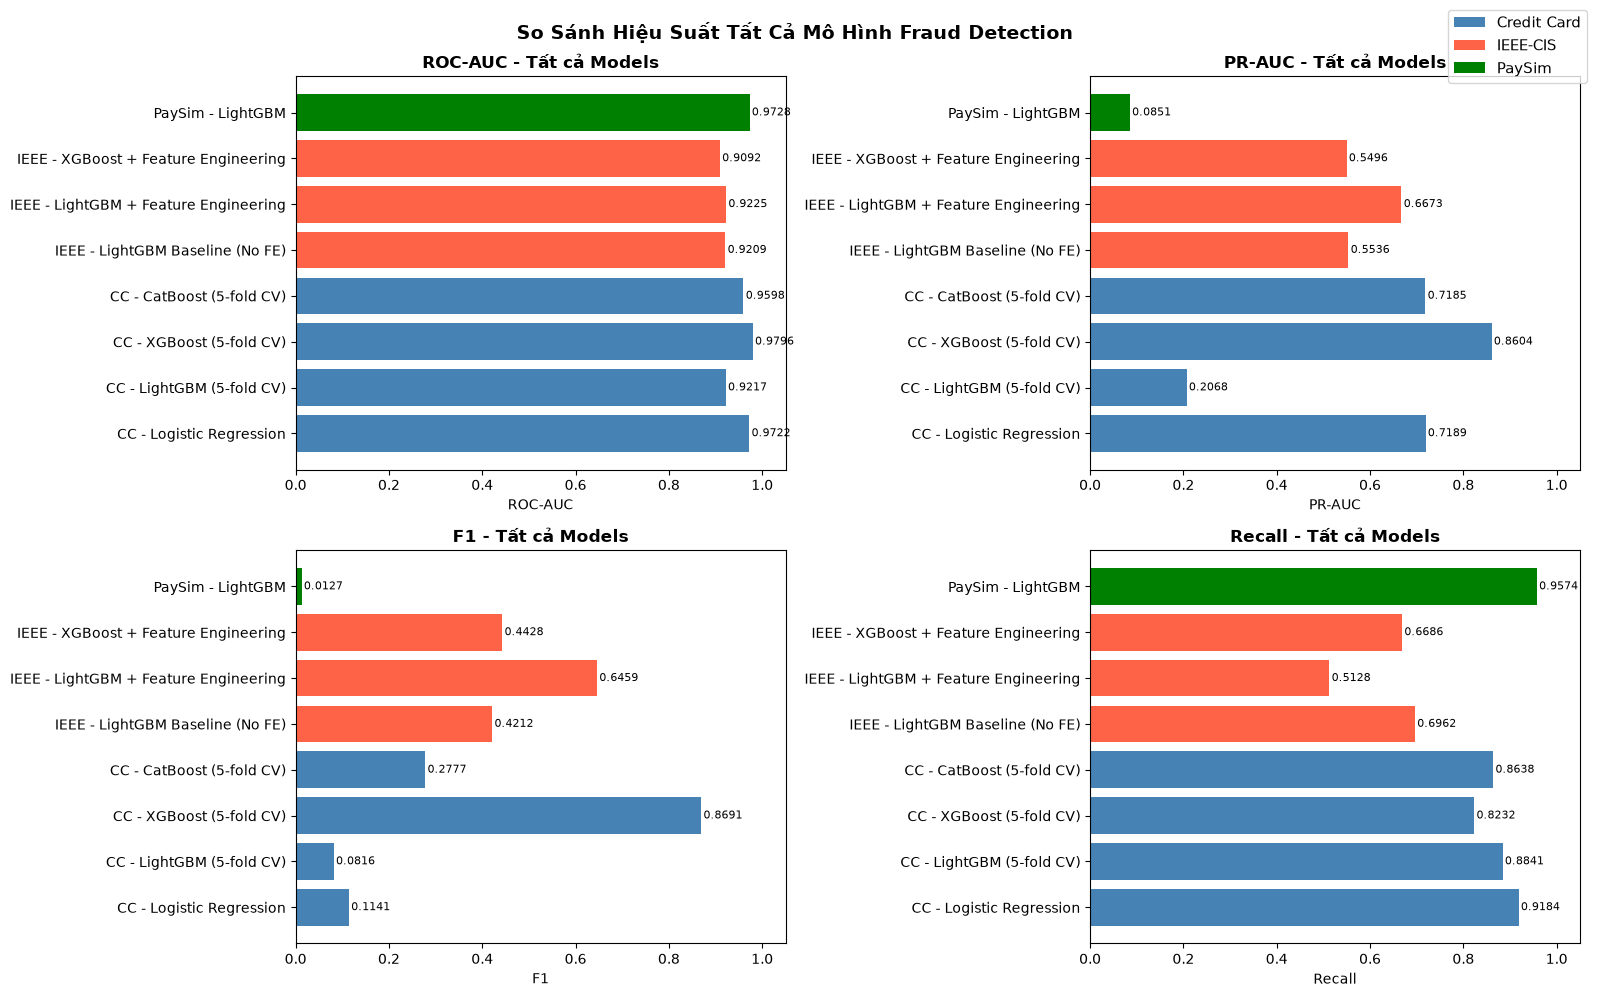

In [126]:
# Biểu đồ so sánh tất cả models
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

metrics = ["ROC-AUC", "PR-AUC", "F1", "Recall"]
colors = {"CC": "steelblue", "IEEE": "tomato", "PaySim": "green"}

for ax, metric in zip(axes.flatten(), metrics):
    bars = ax.barh(
        df_all_results.index,
        df_all_results[metric],
        color=[
            "steelblue" if "CC" in m else "tomato" if "IEEE" in m else "green"
            for m in df_all_results.index
        ],
    )
    ax.set_title(f"{metric} - Tất cả Models", fontsize=12, fontweight="bold")
    ax.set_xlabel(metric)
    ax.set_xlim(0, 1.05)
    for bar, val in zip(bars, df_all_results[metric]):
        ax.text(
            bar.get_width() + 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.4f}",
            va="center",
            fontsize=8,
        )

# Legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="steelblue", label="Credit Card"),
    Patch(facecolor="tomato", label="IEEE-CIS"),
    Patch(facecolor="green", label="PaySim"),
]
fig.legend(
    handles=legend_elements, loc="upper right", bbox_to_anchor=(1, 1), fontsize=11
)
plt.suptitle(
    "So Sánh Hiệu Suất Tất Cả Mô Hình Fraud Detection", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()


## 📝 Nhận Xét Và Kết Luận

### Credit Card Fraud:
- Các mô hình tree-based (LightGBM, XGBoost, CatBoost) vượt trội so với Logistic Regression.
- ROC-AUC cao nhưng PR-AUC thấp hơn nhiều do mất cân bằng class nghiêm trọng (chỉ 0.17% fraud).
- 5-fold CV cho kết quả ổn định và kiểm soát tốt độ biến động giữa các fold.

### IEEE-CIS Fraud:
- Feature Engineering cải thiện đáng kể hiệu suất (đặc biệt PR-AUC tăng rõ rệt).
- Time-based split (theo tháng) là bắt buộc để mô phỏng chính xác kịch bản thực tế và tránh rò rỉ dữ liệu.
- UID features, frequency encoding và chuẩn hóa nhóm thời gian là những features quan trọng hàng đầu.
- **So sánh LightGBM vs XGBoost:** Cả hai mô hình đều đạt hiệu năng xuất sắc trên tập đặc trưng sau FE. LightGBM có ưu thế về tốc độ huấn luyện nhanh, trong khi XGBoost với cấu hình `tree_method="hist"` cho kết quả phân loại rất vững chắc và độ phân tách tốt.

### PaySim:
- **Tuân thủ quy định chống Data Leakage từ Kaggle:** Đã loại bỏ hoàn toàn 4 cột số dư (`oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, `newbalanceDest`) do các giao dịch gian lận bị hủy (cancelled) tạo ra dấu vết số dư bất thường.
- Các đặc trưng thay thế hiệu quả: Giờ giao dịch (`hour`), ngày trong tuần (`day`), loại giao dịch (`type_TRANSFER`, `type_CASH_OUT`), log số tiền, tần suất người nhận (`dest_count`) và độ lệch số tiền so với nhóm.
- LightGBM vẫn đạt hiệu năng cao và phản ánh đúng bài toán phát hiện gian lận trong thực tế.

### Tổng Kết Chung:
- **LightGBM & XGBoost** là những mô hình hiệu quả nhất trên các bài toán gian lận dạng bảng xét về tốc độ lẫn độ chính xác.
- **Feature Engineering** đóng vai trò quyết định, đặc biệt là khi phải loại bỏ các thuộc tính có nguy cơ rò rỉ dữ liệu.
- Với dữ liệu mất cân bằng nghiêm trọng, **PR-AUC** và **Recall** là các chỉ số đánh giá cốt lõi thay vì Accuracy hay ROC-AUC thông thường.
